# Introdução às Redes Neurais e Deep Learning

## O Perceptron Multicamada - Continuação

### Solução de problemas de Regressão/Classificação com Keras & Tensorflow

#### Importação de bibliotecas

In [31]:
import numpy as np
import matplotlib.pyplot as plt
import random
import tensorflow as tf
import keras
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras import backend
from tensorflow.keras.utils import to_categorical

In [13]:
class PrintEvery100(keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        if (epoch + 1) % 100 == 0:
            print(f"Época {epoch + 1}: loss = {logs['loss']:.6f}")

#### **Regressão Linear**

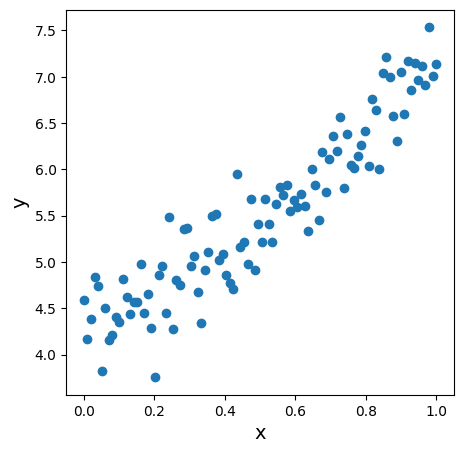

In [3]:
np.random.seed(0)
num_points = 100
X1 = np.linspace(0,1, num_points)
y1 = 4 + 3 * X1 + np.random.randn(num_points)/3

fig = plt.figure(figsize=(5, 5))
plt.scatter(X1, y1)
plt.xlabel('x', fontsize=14)
plt.ylabel('y', fontsize=14)
plt.show()

* Uma camada com um neurônio

In [9]:
np.random.seed(0)
random.seed(0)
tf.random.set_seed(0)
model1 = Sequential()
model1.add(Input(shape=(1,)))
model1.add(Dense(1, activation='linear'))
model1.compile(optimizer='adam', loss='mse', metrics=['mse'])
model1.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                      │ (None, 1)                   │               2 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2 (8.00 B)

 Trainable params: 2 (8.00 B)

 Non-trainable params: 0 (0.00 B)

In [14]:
history1 = model1.fit(X1, y1, epochs=1000, verbose=0,
                      batch_size=X1.shape[0],callbacks=[PrintEvery100()])

Época 100: loss = 16.056931
Época 200: loss = 15.028996
Época 300: loss = 14.048775
Época 400: loss = 13.114788
Época 500: loss = 12.225644
Época 600: loss = 11.379986
Época 700: loss = 10.576477
Época 800: loss = 9.813842
Época 900: loss = 9.090839
Época 1000: loss = 8.406242


32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 


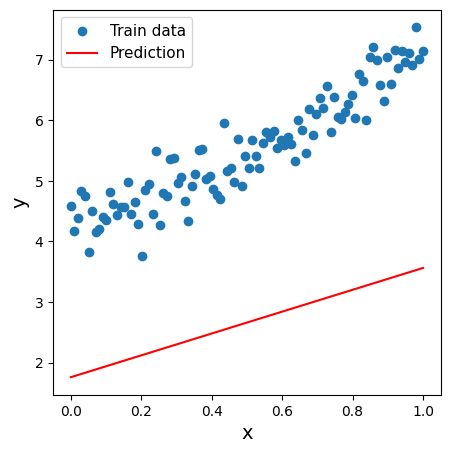

In [15]:
X1_test = np.linspace(0,1, 1000)
yhat1 = model1.predict(X1_test)

fig = plt.figure(figsize=(5, 5))
plt.scatter(X1, y1, label="Train data")
plt.plot(X1_test, yhat1, color="red", label="Prediction")
plt.xlabel('x', fontsize=14)
plt.ylabel('y', fontsize=14)
plt.legend(loc="best", fontsize=11)
plt.show()

* Rede com múltiplas camadas

In [16]:
np.random.seed(15)
random.seed(15)
tf.random.set_seed(15)

input_layer = Input(shape=(1,))
x = Dense(50, activation='linear')(input_layer)
output_layer = Dense(1, activation='linear')(x)
model2 = Model(inputs=input_layer, outputs=output_layer)

model2.compile(optimizer='adam', loss='mse', metrics=['mse'])
model2.summary()

Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)           │ (None, 1)                   │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 50)                  │             100 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 1)                   │              51 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 151 (604.00 B)

 Trainable params: 151 (604.00 B)

 Non-trainable params: 0 (0.00 B)

In [17]:
history2 = model2.fit(X1, y1, epochs=500, verbose=0,
                      batch_size=X1.shape[0],callbacks=[PrintEvery100()])

Época 100: loss = 14.460126
Época 200: loss = 1.503418
Época 300: loss = 0.172998
Época 400: loss = 0.154766
Época 500: loss = 0.143300


32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


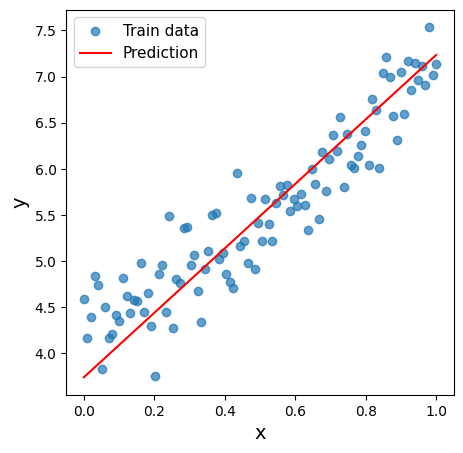

In [18]:
X1_test = np.linspace(0,1, 1000)
yhat1 = model2.predict(X1_test)

fig = plt.figure(figsize=(5, 5))
plt.scatter(X1, y1, label="Train data", alpha=0.7)
plt.plot(X1_test, yhat1, color="red", label="Prediction")
plt.xlabel('x', fontsize=14)
plt.ylabel('y', fontsize=14)
plt.legend(loc="best", fontsize=11)
plt.show()

#### **Regressão quadrática**

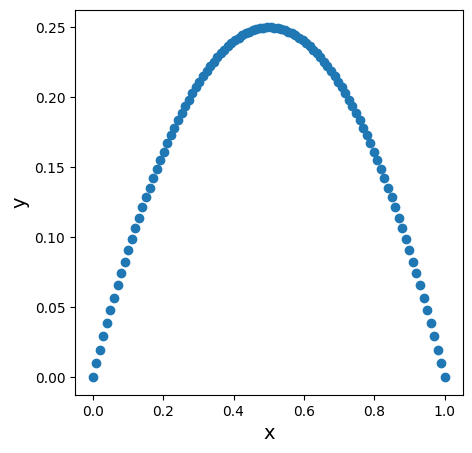

In [19]:
np.random.seed(0)
num_points = 100
X2 = np.linspace(0,1, num_points)
y2 = -(X2-0.5)**2 + 0.25

fig = plt.figure(figsize=(5, 5))
plt.scatter(X2, y2)
plt.xlabel('x', fontsize=14)
plt.ylabel('y', fontsize=14)
plt.show()


* Uma camada com um neurônio

In [21]:
np.random.seed(0)
random.seed(0)
tf.random.set_seed(0)

model3 = Sequential()
model3.add( Input(shape=(1,)))
model3.add(Dense(1, activation='relu', input_shape=(1,)))
model3.compile(optimizer='adam', loss='mse', metrics=['mse'])
model3.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_7 (Dense)                      │ (None, 1)                   │               2 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2 (8.00 B)

 Trainable params: 2 (8.00 B)

 Non-trainable params: 0 (0.00 B)

In [22]:
history3 = model3.fit(X2, y2, epochs=500, verbose=0,
                      batch_size=X2.shape[0],callbacks=[PrintEvery100()])

Época 100: loss = 0.007869
Época 200: loss = 0.006949
Época 300: loss = 0.006494
Época 400: loss = 0.006173
Época 500: loss = 0.005976


32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 


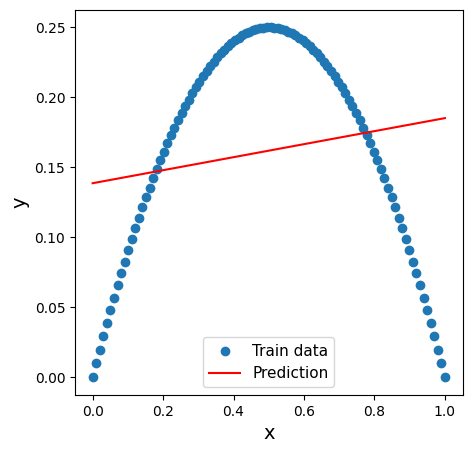

In [24]:
X2_test = np.linspace(0,1, 1000)
yhat2 = model3.predict(X2_test)

fig = plt.figure(figsize=(5, 5))
plt.scatter(X2, y2, label="Train data")
plt.plot(X2_test, yhat2, color="red", label="Prediction")
plt.xlabel('x', fontsize=14)
plt.ylabel('y', fontsize=14)
plt.legend(loc="best", fontsize=11)
plt.show()


* Rede com múltiplas camadas

In [25]:
np.random.seed(15)
random.seed(15)
tf.random.set_seed(15)

input_layer = Input(shape=(1,))
x = Dense(100, activation='relu')(input_layer)
output_layer = Dense(1, activation='linear')(x)
model4 = Model(inputs=input_layer, outputs=output_layer)

model4.compile(optimizer='adam', loss='mse', metrics=['mse'])
model4.summary()

Model: "functional_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)           │ (None, 1)                   │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_8 (Dense)                      │ (None, 100)                 │             200 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_9 (Dense)                      │ (None, 1)                   │             101 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 301 (1.18 KB)

 Trainable params: 301 (1.18 KB)

 Non-trainable params: 0 (0.00 B)

In [26]:
history4 = model4.fit(X2, y2, epochs=1500, verbose=0,
                      batch_size=X2.shape[0],callbacks=[PrintEvery100()])

Época 100: loss = 0.004668
Época 200: loss = 0.003350
Época 300: loss = 0.002414
Época 400: loss = 0.001763
Época 500: loss = 0.001260
Época 600: loss = 0.000872
Época 700: loss = 0.000604
Época 800: loss = 0.000429
Época 900: loss = 0.000307
Época 1000: loss = 0.000219
Época 1100: loss = 0.000158
Época 1200: loss = 0.000115
Época 1300: loss = 0.000086
Época 1400: loss = 0.000065
Época 1500: loss = 0.000050


32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


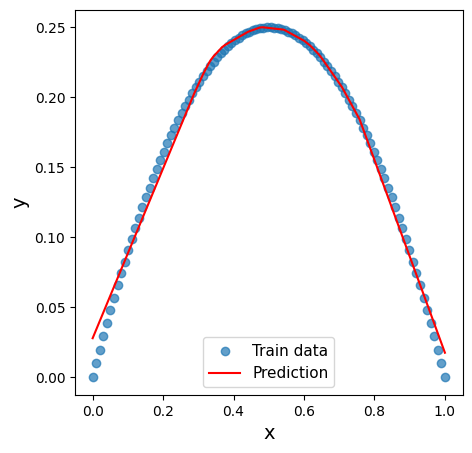

In [28]:
X2_test = np.linspace(0,1, 1000)
yhat2 = model4.predict(X2_test)

fig = plt.figure(figsize=(5, 5))
plt.scatter(X2, y2, label="Train data", alpha=0.7)
plt.plot(X2_test, yhat2, color="red", label="Prediction")
plt.xlabel('x', fontsize=14)
plt.ylabel('y', fontsize=14)
plt.legend(loc="best", fontsize=11)
plt.show()

#### **Classificação (Regressão Logística)**

In [33]:
from keras.datasets import mnist
(X_train, y_train), (X_test, y_test) = mnist.load_data()

In [35]:
# Normalize the images.
train_images = (X_train / 255) - 0.5
test_images = (X_test / 255) - 0.5

# Flatten the images.
train_images = train_images.reshape((-1, 784))
test_images = test_images.reshape((-1, 784))

In [42]:
model5 = Sequential([
  Input(shape=(784,)),
  Dense(64, activation='relu'),
  Dense(64, activation='relu'),
  Dense(10, activation='softmax'),
])
model5.compile(
  optimizer='adam',
  loss='categorical_crossentropy',
  metrics=['accuracy'],
)
model5.summary()

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_16 (Dense)                     │ (None, 64)                  │          50,240 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_17 (Dense)                     │ (None, 64)                  │           4,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_18 (Dense)                     │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 55,050 (215.04 KB)

 Trainable params: 55,050 (215.04 KB)

 Non-trainable params: 0 (0.00 B)

In [43]:
model5.fit(train_images,to_categorical(y_train),epochs=5,batch_size=32,callbacks=[PrintEvery100()])

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.8196 - loss: 0.5734
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9410 - loss: 0.1982
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9547 - loss: 0.1485
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9619 - loss: 0.1247
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9662 - loss: 0.1078


In [46]:
model5.evaluate(
  test_images,
  to_categorical(y_test)
)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9585 - loss: 0.1394


[0.11480965465307236, 0.9642999768257141]

In [47]:
predictions = model5.predict(test_images[:5])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step


In [48]:
# Print our model's predictions.
print(np.argmax(predictions, axis=1)) # [7, 2, 1, 0, 4]

# Check our predictions against the ground truths.
print(y_test[:5]) # [7, 2, 1, 0, 4]

[7 2 1 0 4]
[7 2 1 0 4]
